<a href="https://colab.research.google.com/github/Dimas-091206/Proyek-Akhir-Kelompok-9-Online-Retail-II/blob/main/Varian_3_Klasifikasi_Online_Retail_II_(Perbandingan_dengan_Naive_Bayes).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Akhir Pembelajaran Mesin: Klasifikasi Negara Pelanggan (UK vs non-UK)
## Anggota 3 (Varian Algoritma Pembanding): Naive Bayes vs k-NN terbaik

**Dataset:** Online Retail II (data pelanggan hasil agregasi, sudah bersih)
**Target:** `kelompok_negara` (UK / non-UK) | **Fitur (6):** recency, frekuensi, total_belanja, produk_unik, total_item, n_faktur_batal

**Tugas:** membangun Naive Bayes pada data yang sama, lalu membandingkan hasilnya dengan k-NN terbaik dari Anggota 2 (k = 9).
Pembagian data (80:20, berstrata, `random_state=42`) dan garis dasar 91,15% **sama persis** dengan Anggota 1 dan 2, sehingga perbandingan adil.

## Langkah 1. Impor pustaka dan tetapkan konstanta

`K_TERBAIK = 9` diambil dari Langkah 11 notebook Anggota 2 (akurasi data uji tertinggi, seri dengan k = 11 dan 15, dipilih yang terkecil).
Model k-NN **dilatih ulang di notebook ini** pada data yang sama, bukan menyalin angka, supaya kedua model dinilai pada data uji yang identik.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
K_TERBAIK = 9      # k terbaik dari Anggota 2
FITUR = ["recency", "frekuensi", "total_belanja", "produk_unik", "total_item", "n_faktur_batal"]

## Langkah 2. Mengambil dataset

Memakai berkas `data_bersih_pelanggan.csv` yang sama dengan Anggota 1 dan 2 (hasil notebook EDA). Jika berkas sudah ada di folder kerja Colab,
langsung dibaca; jika belum, diunduh otomatis dari Google Drive dengan `FILE_ID` yang sama dengan Anggota 2.
Pemeriksaan ukuran (5.852 x 14) memastikan data identik dengan yang dipakai rekan.

In [2]:
FILE_ID = "1ce3K3K2Vet0XDI7uSp6A44pUXnJC3BpW"   # sama dengan Anggota 2; ganti jika file Drive sendiri
OUTPUT = "data_bersih_pelanggan.csv"

if not os.path.exists(OUTPUT):
    import gdown
    gdown.download(id=FILE_ID, output=OUTPUT, quiet=False)

df = pd.read_csv(OUTPUT)
print("Ukuran data:", df.shape, "(harus 5852 x 14)")
print(df["kelompok_negara"].value_counts())
df.head()

Downloading...
From: https://drive.google.com/uc?id=1ce3K3K2Vet0XDI7uSp6A44pUXnJC3BpW
To: /content/data_bersih_pelanggan.csv
100%|██████████| 481k/481k [00:00<00:00, 6.74MB/s]

Ukuran data: (5852, 14) (harus 5852 x 14)
kelompok_negara
UK        5334
non-UK     518
Name: count, dtype: int64


,Customer ID,total_belanja,frekuensi,recency,tenure_hari,produk_unik,total_item,n_faktur_batal,rata_nilai_faktur,nilai_batal,total_belanja_bersih,negara,n_negara,kelompok_negara
0,12346,77352.96,3,325,647,25,74239,1.0,25784.32000,-77183.60,169.36,United Kingdom,1,UK
1,12347,4921.53,8,2,404,126,2967,0.0,615.19125,0.00,4921.53,Iceland,1,non-UK
2,12348,1658.40,5,75,438,24,2704,0.0,331.68000,0.00,1658.40,Finland,1,non-UK
3,12349,3678.69,3,18,589,137,1621,1.0,1226.23000,-24.15,3654.54,Italy,1,non-UK
4,12350,294.40,1,310,310,16,196,0.0,294.40000,0.00,294.40,Norway,1,non-UK


## Langkah 3. Fitur, target, dan pembagian data (identik dengan Anggota 1 dan 2)

Target: **UK = 0, non-UK = 1** (non-UK = kelas positif). `negara` dan `n_negara` tidak dipakai karena menyusun target (kebocoran data).
Pembagian 80:20 dengan `stratify=y` dan `random_state=42`. Baris `assert` menggagalkan sel jika ukuran pembagian berbeda dari rekan,
jadi perbandingan model dijamin memakai data uji yang sama.

In [3]:
X = df[FITUR]
y = (df["kelompok_negara"] == "non-UK").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
assert X_train.shape[0] == 4681 and X_test.shape[0] == 1171, "Pembagian berbeda dengan Anggota 1 dan 2!"

BASELINE = (y == 0).mean() * 100          # seluruh data
BASELINE_UJI = (y_test == 0).mean() * 100 # data uji
print(f"Garis dasar (tebak selalu UK): {BASELINE:.2f}% (seluruh data) | {BASELINE_UJI:.2f}% (data uji)")
print(f"Pelanggan non-UK pada data uji: {int(y_test.sum())} dari {len(y_test)}")

Data latih: (4681, 6) | Data uji: (1171, 6)
Garis dasar (tebak selalu UK): 91.15% (seluruh data) | 91.12% (data uji)
Pelanggan non-UK pada data uji: 104 dari 1171


## Langkah 4. Membangun Naive Bayes

Dipakai **Gaussian Naive Bayes** karena keenam fitur bersifat numerik kontinu. Cara kerjanya: untuk tiap kelas, model mempelajari rata-rata dan
simpangan baku tiap fitur, lalu menghitung peluang kelas dengan mengalikan peluang tiap fitur (**asumsi fitur saling bebas**).
Naive Bayes tidak berbasis jarak, jadi **tidak memerlukan penskalaan** (berbeda dengan k-NN); sel di bawah membuktikannya.

Fungsi `hitung_metrik` dipakai untuk semua model agar rumus evaluasinya sama. Karena kelasnya timpang, evaluasi tidak berhenti di akurasi:
dihitung juga precision, recall, F1 kelas non-UK, balanced accuracy, dan ROC-AUC.

In [4]:
def hitung_metrik(nama, y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"model": nama,
            "akurasi": accuracy_score(y_true, y_pred),
            "precision_nonUK": precision_score(y_true, y_pred, zero_division=0),
            "recall_nonUK": recall_score(y_true, y_pred, zero_division=0),
            "f1_nonUK": f1_score(y_true, y_pred, zero_division=0),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_proba),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)
proba_nb = nb.predict_proba(X_test)[:, 1]
metrik_nb = hitung_metrik("Naive Bayes (Gaussian)", y_test, pred_nb, proba_nb)

print(f"Prior kelas yang dipelajari: UK = {nb.class_prior_[0]:.4f} | non-UK = {nb.class_prior_[1]:.4f}")
print("\nRata-rata fitur per kelas (yang dipelajari model):")
display(pd.DataFrame(nb.theta_, index=["UK", "non-UK"], columns=FITUR).round(1))

# Bukti: Naive Bayes tidak butuh penskalaan
sc = StandardScaler().fit(X_train)
nb_skala = GaussianNB().fit(sc.transform(X_train), y_train)
pred_skala = nb_skala.predict(sc.transform(X_test))
print(f"\nAkurasi tanpa penskalaan : {accuracy_score(y_test, pred_nb)*100:.2f}% | "
      f"TP = {int(((pred_nb==1)&(y_test==1)).sum())}")
print(f"Akurasi dengan penskalaan: {accuracy_score(y_test, pred_skala)*100:.2f}% | "
      f"TP = {int(((pred_skala==1)&(y_test==1)).sum())}  -> hampir sama, penskalaan tidak berpengaruh berarti")

Prior kelas yang dipelajari: UK = 0.9116 | non-UK = 0.0884

Rata-rata fitur per kelas (yang dipelajari model):


,recency,frekuensi,total_belanja,produk_unik,total_item,n_faktur_batal
UK,200.9,6.1,2632.8,80.4,1571.3,1.2
non-UK,181.6,5.6,5235.8,80.2,3740.7,1.4



Akurasi tanpa penskalaan : 89.92% | TP = 4
Akurasi dengan penskalaan: 89.84% | TP = 4  -> hampir sama, penskalaan tidak berpengaruh berarti


## Langkah 5. Melatih ulang k-NN terbaik dari Anggota 2 (k = 9)

Pipeline yang sama dengan Anggota 2: `StandardScaler` (di-fit hanya pada data latih) lalu k-NN dengan k = 9.
Hasilnya harus cocok dengan Langkah 11 notebook Anggota 2 (akurasi 91,12%, TP = 0, FN = 104, FP = 0, TN = 1067).

In [5]:
knn = Pipeline([("scaler", StandardScaler()),
                ("knn", KNeighborsClassifier(n_neighbors=K_TERBAIK))])
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)
proba_knn = knn.predict_proba(X_test)[:, 1]
metrik_knn = hitung_metrik(f"k-NN (k={K_TERBAIK})", y_test, pred_knn, proba_knn)

print(f"k-NN k={K_TERBAIK}: akurasi = {metrik_knn['akurasi']*100:.2f}% | "
      f"TP = {metrik_knn['TP']}, FN = {metrik_knn['FN']}, FP = {metrik_knn['FP']}, TN = {metrik_knn['TN']}")

k-NN k=9: akurasi = 91.12% | TP = 0, FN = 104, FP = 0, TN = 1067


## Langkah 6. Perbandingan Naive Bayes vs k-NN pada data uji

Tabel memuat tiga baris: garis dasar (model bodoh yang selalu menebak UK), Naive Bayes, dan k-NN terbaik.
**Cara membaca:** akurasi saja menyesatkan karena garis dasarnya sudah 91%. Lihat recall non-UK (berapa dari 104 pelanggan non-UK yang berhasil dikenali)
dan precision non-UK (dari yang ditandai non-UK, berapa yang benar).

,akurasi,precision_nonUK,recall_nonUK,f1_nonUK,balanced_acc,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
Garis dasar (selalu UK),0.9112,0.0000,0.0000,0.0000,0.5000,0.5000,0,0,104,1067
Naive Bayes (Gaussian),0.8992,0.1818,0.0385,0.0635,0.5108,0.5819,4,18,100,1049
k-NN (k=9),0.9112,0.0000,0.0000,0.0000,0.5000,0.5648,0,0,104,1067


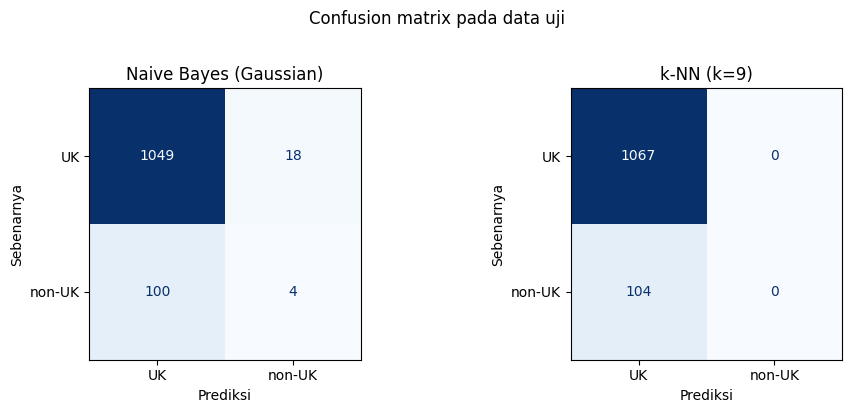

In [6]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
metrik_dummy = hitung_metrik("Garis dasar (selalu UK)", y_test, dummy.predict(X_test),
                             dummy.predict_proba(X_test)[:, 1])

tabel = pd.DataFrame([metrik_dummy, metrik_nb, metrik_knn]).set_index("model")
display(tabel.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nama, pred in zip(axes, ["Naive Bayes (Gaussian)", f"k-NN (k={K_TERBAIK})"], [pred_nb, pred_knn]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=["UK", "non-UK"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(nama); ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
plt.suptitle("Confusion matrix pada data uji", y=1.02)
plt.tight_layout(); plt.show()

## Langkah 7. Kurva ROC (kemampuan memisahkan kelas tanpa bergantung pada ambang)

Akurasi, precision, dan recall bergantung pada ambang keputusan 0,5. ROC-AUC mengukur kemampuan model **mengurutkan** pelanggan non-UK di atas UK pada semua ambang.
AUC = 0,5 berarti sama dengan menebak acak (garis putus-putus); AUC = 1 berarti sempurna.

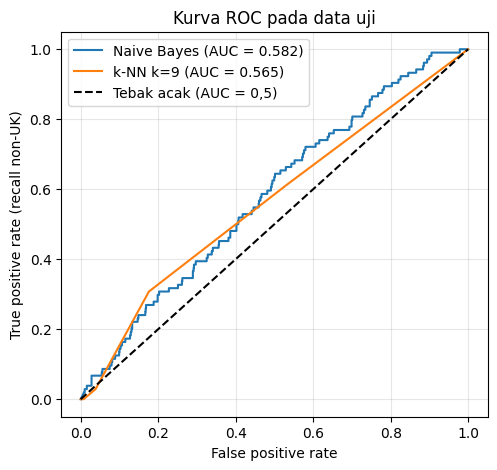

In [7]:
fpr_nb, tpr_nb, _ = roc_curve(y_test, proba_nb)
fpr_kn, tpr_kn, _ = roc_curve(y_test, proba_knn)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr_nb, tpr_nb, label=f"Naive Bayes (AUC = {metrik_nb['roc_auc']:.3f})")
plt.plot(fpr_kn, tpr_kn, label=f"k-NN k={K_TERBAIK} (AUC = {metrik_knn['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Tebak acak (AUC = 0,5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall non-UK)")
plt.title("Kurva ROC pada data uji"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## Langkah 8. Validasi silang 5-fold (perbandingan yang lebih stabil)

Data uji hanya memuat 104 pelanggan non-UK, sehingga selisih beberapa pelanggan (mis. TP = 4 vs 0) bisa kebetulan. Validasi silang berstrata
mengulang evaluasi pada 5 pembagian berbeda dan memakai seluruh 5.852 pelanggan. Scaler k-NN berada di dalam *pipeline* agar di-fit ulang
di setiap lipatan (tanpa kebocoran data).

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_cv = {
    "Garis dasar (selalu UK)": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes (Gaussian)": GaussianNB(),
    f"k-NN (k={K_TERBAIK})": Pipeline([("scaler", StandardScaler()),
                                       ("knn", KNeighborsClassifier(n_neighbors=K_TERBAIK))]),
}
baris_cv = []
for nama, m in model_cv.items():
    s = cross_validate(m, X, y, cv=skf, scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    baris_cv.append({"model": nama,
                     "akurasi_mean": s["test_accuracy"].mean(), "akurasi_std": s["test_accuracy"].std(),
                     "precision_nonUK": s["test_precision"].mean(), "recall_nonUK": s["test_recall"].mean(),
                     "f1_nonUK": s["test_f1"].mean(), "roc_auc": s["test_roc_auc"].mean()})
hasil_cv = pd.DataFrame(baris_cv).set_index("model")
display(hasil_cv.round(4))

,akurasi_mean,akurasi_std,precision_nonUK,recall_nonUK,f1_nonUK,roc_auc
model,,,,,,
Garis dasar (selalu UK),0.9115,0.0004,0.0000,0.0000,0.0000,0.5000
Naive Bayes (Gaussian),0.8898,0.0114,0.0467,0.0154,0.0232,0.5158
k-NN (k=9),0.9110,0.0006,0.1667,0.0039,0.0076,0.5718


## Langkah 9. Memeriksa asumsi Naive Bayes

Naive Bayes mengasumsikan (1) fitur **saling bebas** dan (2) tiap fitur **berdistribusi normal** pada tiap kelas. Dua pemeriksaan di bawah
menunjukkan seberapa jauh asumsi itu terpenuhi pada data ini. Ini bahan untuk menjelaskan **mengapa** hasil Naive Bayes seperti yang tampak.

In [9]:
korelasi = X_train.corr()
pasangan = korelasi.where(np.triu(np.ones(korelasi.shape), 1).astype(bool)).stack()
print("Pasangan fitur berkorelasi |r| > 0,6 (asumsi kebebasan dilanggar):")
display(pasangan[pasangan.abs() > 0.6].sort_values(key=abs, ascending=False).rename("korelasi").to_frame().round(2))

print("Kemencengan (skewness) fitur pada data latih (distribusi normal bernilai sekitar 0):")
display(X_train.skew().round(2).to_frame("skewness").T)

Pasangan fitur berkorelasi |r| > 0,6 (asumsi kebebasan dilanggar):


korelasi
total_belanja total_item          0.86
frekuensi     n_faktur_batal      0.69
              total_belanja       0.61

Kemencengan (skewness) fitur pada data latih (distribusi normal bernilai sekitar 0):


,recency,frekuensi,total_belanja,produk_unik,total_item,n_faktur_batal
skewness,0.89,7.75,27.35,3.45,24.07,7.54


## Langkah 10. Ringkasan perbandingan (otomatis dari hasil di atas)

In [10]:
a_nb, a_kn = metrik_nb["akurasi"] * 100, metrik_knn["akurasi"] * 100
print(f"Garis dasar data uji      : {BASELINE_UJI:.2f}%")
print(f"Akurasi Naive Bayes       : {a_nb:.2f}% ({a_nb - BASELINE_UJI:+.2f} poin terhadap garis dasar)")
print(f"Akurasi k-NN (k={K_TERBAIK})        : {a_kn:.2f}% ({a_kn - BASELINE_UJI:+.2f} poin terhadap garis dasar)")
print(f"\nPelanggan non-UK terkenali (dari {int(y_test.sum())}): "
      f"Naive Bayes = {metrik_nb['TP']} | k-NN = {metrik_knn['TP']}")
print(f"Pelanggan UK salah ditandai non-UK : Naive Bayes = {metrik_nb['FP']} | k-NN = {metrik_knn['FP']}")
print(f"ROC-AUC data uji   : Naive Bayes = {metrik_nb['roc_auc']:.3f} | k-NN = {metrik_knn['roc_auc']:.3f}")
print(f"ROC-AUC validasi silang: Naive Bayes = {hasil_cv.loc['Naive Bayes (Gaussian)','roc_auc']:.3f} | "
      f"k-NN = {hasil_cv.loc[f'k-NN (k={K_TERBAIK})','roc_auc']:.3f}")

Garis dasar data uji      : 91.12%
Akurasi Naive Bayes       : 89.92% (-1.20 poin terhadap garis dasar)
Akurasi k-NN (k=9)        : 91.12% (+0.00 poin terhadap garis dasar)

Pelanggan non-UK terkenali (dari 104): Naive Bayes = 4 | k-NN = 0
Pelanggan UK salah ditandai non-UK : Naive Bayes = 18 | k-NN = 0
ROC-AUC data uji   : Naive Bayes = 0.582 | k-NN = 0.565
ROC-AUC validasi silang: Naive Bayes = 0.516 | k-NN = 0.572


## Langkah 11. Kesimpulan

- **Akurasi:** Dalam hal akurasi, k-NN dengan k=9 (nilai k terkecil dan terbaik) hasilnya lebih akurat pada angka 91.12% di data uji, sedangkan Naive Bayes hanya mendapatkan nilai 89,92%. tapi hanya karena menebak UK untuk semua pelanggan (TP = 0, FP = 0), sehingga sama dengan garis dasar. Naive bayes justru 1,20 poin di bawah garis dasar.

- **Kemampuan Mengenali Target Minor (Non-UK):** Naive Bayes berhasil menemukan 4 dari 104 pelanggan Non-UK (recall= 3,85, precision=18,2%) dengan 18 pelanggan UK salah ditandai. Sedangkan k-NN tidak menemukan satu pun yang artinya recall = 0%. dapat disimpulkan hanya Naive Bayes lah yang mampu mengenali Target Minor utama itu (Non-UK) walaupun sangat lemah.

- **Kemampuan memisahkan kelas:** ROC-AUC kedua model dekat dengan nilai 0,5 (data uji: Naive Bayes=0,516 dan k-NN=0,572). Akan tetapi pada validasi silang urutanny malah berbalik (Naive Bayes=0,516, k-NN=0,572), keunggulan tidak dapat dilihat karena kebetulan selisihnya sebanding.

- **Penyebab:** asumsi Naive Bayes dilanggar karena fitur total_belanja dan total _item hanya berkorelasi 0,86 dan keenam fitur memang hampir tidak memisahkan Uk dari non-UK (sesuai dengan temuan pada EDA)

- **Jawaban Akhir:** Pada akhirnya akurasi garis dasar tidak bisa dikalahkan baik oleh Naive Bayes ataupun k-NN. Jika tujuannya mengenali pelanggan non-UK, Naive Bayes sedikit lebih baik pada data uji, namu apabla tujuannya akurasi k-NN, tapi itu hanya karean k-NN selalu menebak UK. keduanya belum layak dipakai di kasus nyata.